# Unit 3 – Polynomial Regression
**Module:** Machine Learning (ML_PCOM7E)  |  **e-Portfolio activity:** Correlation and Regression (4 of 4)

**Aim:** model a non-linear relationship by adding polynomial terms, and use the train/test gap to see under- and over-fitting as the degree changes.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
rng_seed = 42   # change me
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
N, NOISE = 80, 0.25           # <- change sample size and noise
rng=np.random.default_rng(rng_seed)
x=np.sort(rng.uniform(-3,3,N)); y=0.5*x**3-x**2+2*x+rng.normal(0,NOISE*5,N)  # true cubic
X=x.reshape(-1,1); Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.3,random_state=1)
def fit(deg): return make_pipeline(PolynomialFeatures(deg),LinearRegression()).fit(Xtr,ytr)
rows=[]
for deg in range(1,11):
    mdl=fit(deg); rows.append((deg,mean_squared_error(ytr,mdl.predict(Xtr))**.5,mean_squared_error(yte,mdl.predict(Xte))**.5,r2_score(yte,mdl.predict(Xte))))
tab=pd.DataFrame(rows,columns=["degree","train_RMSE","test_RMSE","test_R2"]).round(3); print(tab.to_string(index=False))
best=int(tab.loc[tab.test_RMSE.idxmin(),"degree"]); print("\nBest degree by test RMSE:",best)

 degree  train_RMSE  test_RMSE  test_R2
      1       3.300      3.232    0.702
      2       2.352      2.006    0.885
      3       1.122      1.262    0.955
      4       1.114      1.219    0.958
      5       1.114      1.225    0.957
      6       1.111      1.222    0.957
      7       1.103      1.253    0.955
      8       1.086      1.268    0.954
      9       1.070      1.334    0.949
     10       1.069      1.335    0.949

Best degree by test RMSE: 4


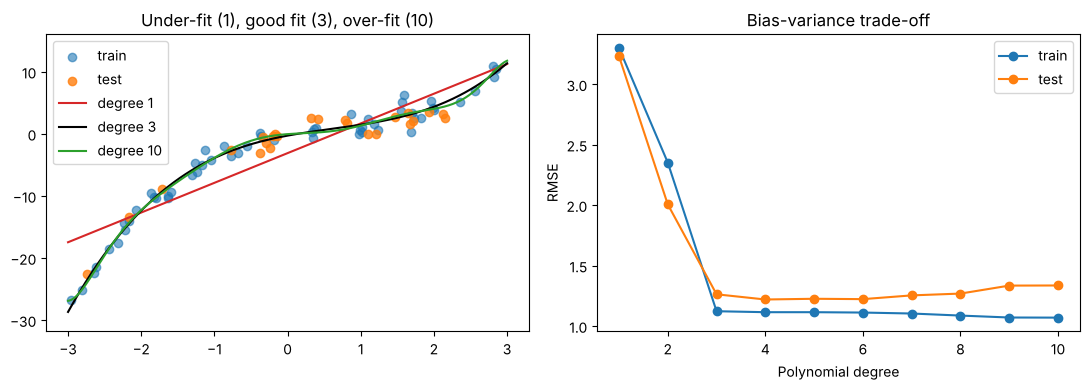

In [2]:
xs=np.linspace(-3,3,300).reshape(-1,1)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(Xtr,ytr,alpha=.6,label="train"); ax[0].scatter(Xte,yte,alpha=.8,label="test")
for deg,c in [(1,"tab:red"),(3,"k"),(10,"tab:green")]: ax[0].plot(xs,fit(deg).predict(xs),c=c,label=f"degree {deg}")
ax[0].set_ylim(y.min()-5,y.max()+5); ax[0].legend(); ax[0].set_title("Under-fit (1), good fit (3), over-fit (10)")
ax[1].plot(tab.degree,tab.train_RMSE,"o-",label="train"); ax[1].plot(tab.degree,tab.test_RMSE,"o-",label="test"); ax[1].set(xlabel="Polynomial degree",ylabel="RMSE",title="Bias-variance trade-off"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig_polyreg.png",dpi=130); plt.show()

## Interpretation
* A straight line (degree 1) under-fits: both train and test RMSE are high (3.3 and 3.2, against about 1.2 for the cubic) because the true relationship is cubic.
* Training error keeps falling as the degree grows, but test RMSE bottoms out at degrees 3-6 (about 1.22-1.26) and then creeps up to 1.34 by degree 10 while training error keeps shrinking: high-degree models start to memorise noise. The gain from degree 3 to 4 is negligible, so the simpler cubic is the sensible choice.
* Choosing the degree on **test/validation** error, not training error, is the practical safeguard; cross-validation (Unit 11) formalises this.
* Try raising `NOISE` or lowering `N`: over-fitting appears at lower degrees when data are scarce or noisy.